# Converting Bruker timsTOF TSF imaging data to imzML — on a Mac

Bruker's `tdf-sdk` ships `timsdata.dll` (Windows) and `libtimsdata.so` (Linux) and nothing else,
so the usual route from a MALDI imaging `.d` folder to imzML does not run on macOS at all —
Intel or Apple Silicon.

This notebook does the conversion in pure Python using `pytsf` (this repository), which
reimplements the TSF reading path with no vendor binary, plus
[`pyimzML`](https://github.com/alexandrovteam/pyimzML) for writing the imzML/ibd pair.

**What you get:** a `.imzML` + `.ibd` pair that opens in SCiLS, Cardinal, METASPACE, MSiReader,
or anything else that reads imzML.

As shipped, this notebook runs against a small **synthetic** imaging dataset generated by
`examples/make_demo_dataset.py`, so it works out of the box with no data of your own and
nothing confidential in the outputs. Point `ANALYSIS_DIR` at a real `.d` folder to use it
for real.

**Requirements**

```bash
pip install -e .            # pytsf, from the root of this repository
pip install pyimzml matplotlib
```

## 1. Point this at your data

The only thing you need to change. `ANALYSIS_DIR` is the `.d` folder itself (the one
containing `analysis.tsf` and `analysis.tsf_bin`).

In [1]:
from pathlib import Path

# ---------------------------------------------------------------------------
# Point these at your own data.
#
# The defaults use the small synthetic imaging dataset produced by
# examples/make_demo_dataset.py, so this notebook runs end to end with no real
# data. Generate it first with:
#
#     python examples/make_demo_dataset.py demo_imaging.d
#
# ---------------------------------------------------------------------------

ANALYSIS_DIR = Path("demo_imaging.d")          # <-- your .d folder
OUTPUT_IMZML = Path("out/converted.imzML")     # <-- where to write

# Keep every peak, or drop the noise floor to shrink the output.
# None = keep everything; otherwise an absolute intensity threshold.
MIN_INTENSITY = None

# Keep only peaks inside this m/z window (None = the full acquisition range).
MZ_RANGE = None        # e.g. (300.0, 1000.0)

## 2. Open the dataset and look at what's in it

In [2]:
import numpy as np
from pytsf import TsfData

tsf = TsfData(ANALYSIS_DIR)
meta = tsf.meta

print(f"spectra            : {len(tsf)}")
print(f"instrument         : {meta.global_metadata.get('InstrumentName')}")
print(f"acquisition sw     : {meta.global_metadata.get('AcquisitionSoftware')} "
      f"{meta.global_metadata.get('AcquisitionSoftwareVersion')}")
print(f"MALDI imaging      : {meta.is_maldi}")
print(f"line / profile     : {meta.has_line_spectra} / {meta.has_profile_spectra}")
print(f"m/z range          : {meta.mz_acq_range}")
print(f"polarity           : {meta.frame(meta.frame_ids()[0]).polarity}")

if not meta.is_maldi:
    raise SystemExit("No MaldiFrameInfo table: this is not an imaging dataset, "
                     "so there are no pixel coordinates to write into imzML.")
if not meta.has_line_spectra:
    raise SystemExit("No line spectra. See the 'Profile data' note at the end.")

spectra            : 1536
instrument         : synthetic
acquisition sw     : pytsf-demo 0
MALDI imaging      : True
line / profile     : True / False
m/z range          : (300.0, 1000.0)
polarity           : +


## 3. Read the pixel grid

imzML needs an (x, y) for every spectrum. In TSF these live in `MaldiFrameInfo`, a
table the acquisition software writes alongside the documented core schema.

imzML coordinates are 1-based, so we shift the grid to start at 1.

In [3]:
rows = meta.table("MaldiFrameInfo")
coords = {r["Frame"]: (r["XIndexPos"], r["YIndexPos"]) for r in rows}

xs = np.array([c[0] for c in coords.values()])
ys = np.array([c[1] for c in coords.values()])
x0, y0 = xs.min(), ys.min()
width, height = xs.max() - x0 + 1, ys.max() - y0 + 1

print(f"pixels   : {len(coords)}")
print(f"grid     : {width} x {height}  ({width * height} positions, "
      f"{len(coords)} acquired)")
print(f"x range  : {xs.min()}..{xs.max()}")
print(f"y range  : {ys.min()}..{ys.max()}")

pixels   : 1536
grid     : 48 x 32  (1536 positions, 1536 acquired)
x range  : 1..48
y range  : 1..32


## 4. Look at one spectrum before converting anything

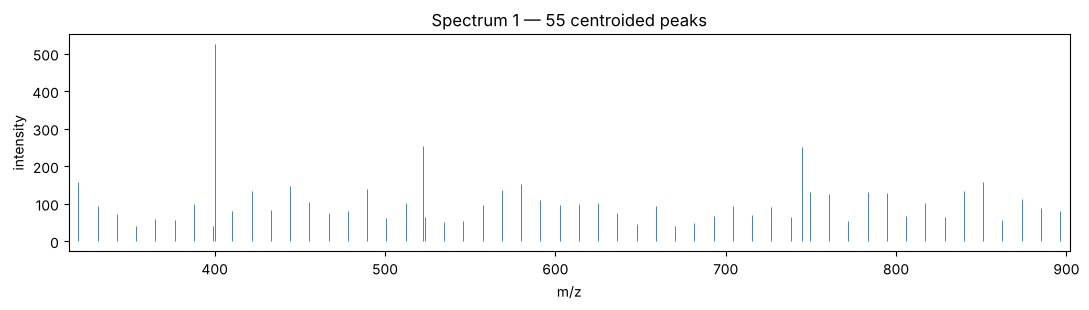

m/z     : 320.0038 .. 896.3002
TIC     : 5,753


In [4]:
import matplotlib.pyplot as plt

fid = meta.frame_ids()[0]
mz, intensity = tsf.line_spectrum_mz(fid)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.vlines(mz, 0, intensity, lw=0.6, color="#2b6cb0")
ax.set_xlabel("m/z"); ax.set_ylabel("intensity")
ax.set_title(f"Spectrum {fid} — {len(mz)} centroided peaks")
ax.margins(x=0.01)
plt.tight_layout(); plt.show()

print(f"m/z     : {mz.min():.4f} .. {mz.max():.4f}")
print(f"TIC     : {intensity.sum():,.0f}")

## 5. Convert to imzML

We write **processed** mode: each spectrum carries its own m/z array. That is the right
choice for centroided data, where every pixel has a different peak list.

(`continuous` mode — one shared m/z axis — only applies to profile data on a common grid.
`pytsf` fits one calibration per analysis, so its profile axis *is* shared across spectra and
would suit `continuous` mode; see the note on profile data at the end.)

In [5]:
import time
from pyimzml.ImzMLWriter import ImzMLWriter

OUTPUT_IMZML.parent.mkdir(parents=True, exist_ok=True)
polarity = {"+": "positive", "-": "negative"}.get(
    meta.frame(meta.frame_ids()[0]).polarity)

t0 = time.time()
n_written = n_skipped = 0
n_peaks = 0

with ImzMLWriter(str(OUTPUT_IMZML), mode="processed",
                 spec_type="centroid", polarity=polarity) as writer:
    for i, fid in enumerate(sorted(coords)):
        mz, intensity = tsf.line_spectrum_mz(fid)

        if MZ_RANGE is not None:
            keep = (mz >= MZ_RANGE[0]) & (mz <= MZ_RANGE[1])
            mz, intensity = mz[keep], intensity[keep]
        if MIN_INTENSITY is not None:
            keep = intensity >= MIN_INTENSITY
            mz, intensity = mz[keep], intensity[keep]

        if mz.size == 0:
            n_skipped += 1
            continue

        x, y = coords[fid]
        writer.addSpectrum(mz, intensity, (x - x0 + 1, y - y0 + 1))
        n_written += 1
        n_peaks += mz.size

        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(coords)} ({time.time() - t0:.0f}s)")

dt = time.time() - t0
print(f"\nwrote {n_written:,} spectra ({n_peaks:,} peaks) in {dt:.1f}s")
if n_skipped:
    print(f"skipped {n_skipped} empty spectra")
for p in (OUTPUT_IMZML, OUTPUT_IMZML.with_suffix(".ibd")):
    print(f"  {p.name}: {p.stat().st_size / 1e6:.1f} MB")

  500/1536 (0s)


  1000/1536 (0s)


  1500/1536 (0s)

wrote 1,536 spectra (84,480 peaks) in 0.4s
  converted.imzML: 3.6 MB
  converted.ibd: 1.0 MB


## 6. Verify the conversion

Read the imzML back and check it against the source. Worth doing once on any new dataset —
a silently truncated `.ibd` looks fine until someone tries to use it.

In [6]:
from pyimzml.ImzMLParser import ImzMLParser

parser = ImzMLParser(str(OUTPUT_IMZML))
print(f"imzML contains {len(parser.coordinates)} spectra")
assert len(parser.coordinates) == n_written

frame_ids = sorted(coords)
check = [0, 1, len(parser.coordinates) // 2, len(parser.coordinates) - 1]
mismatches = 0

for k in check:
    mz_i, int_i = parser.getspectrum(k)
    mz_t, int_t = tsf.line_spectrum_mz(frame_ids[k])
    if MZ_RANGE is not None:
        keep = (mz_t >= MZ_RANGE[0]) & (mz_t <= MZ_RANGE[1])
        mz_t, int_t = mz_t[keep], int_t[keep]
    if MIN_INTENSITY is not None:
        keep = int_t >= MIN_INTENSITY
        mz_t, int_t = mz_t[keep], int_t[keep]

    ok = (np.array_equal(np.asarray(mz_i), mz_t)
          and np.array_equal(np.asarray(int_i), int_t))
    print(f"  spectrum {k:>5}: {'exact match' if ok else 'MISMATCH'} "
          f"({len(mz_i)} peaks)")
    mismatches += (not ok)

print("\nOK — imzML round-trips exactly" if not mismatches
      else f"\n{mismatches} MISMATCHES — do not use this file")

imzML contains 1536 spectra
  spectrum     0: exact match (55 peaks)
  spectrum     1: exact match (55 peaks)
  spectrum   768: exact match (55 peaks)
  spectrum  1535: exact match (55 peaks)

OK — imzML round-trips exactly


## 7. Render an ion image from the converted file

imaging m/z: [400.23, 522.35, 744.57]


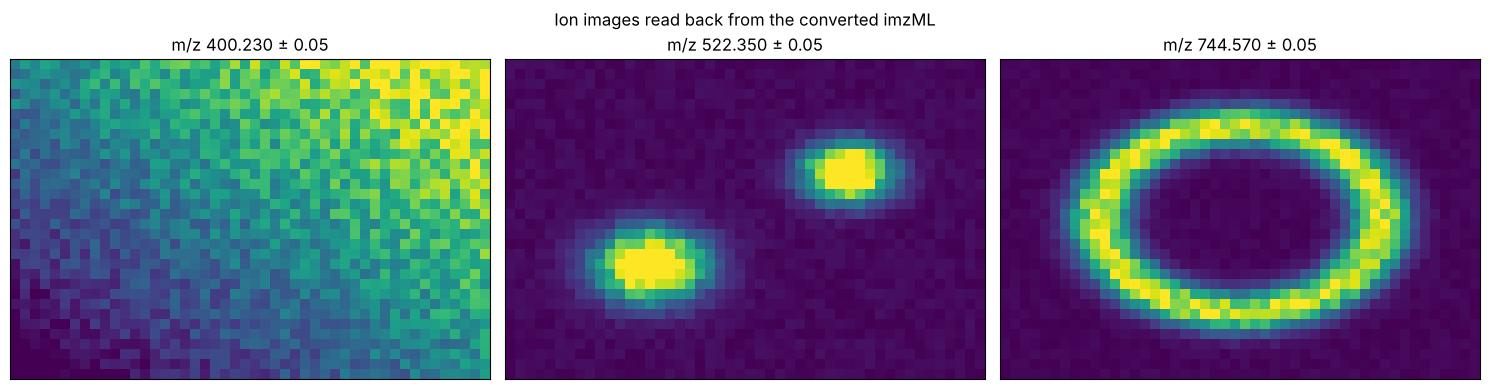

In [7]:
from pyimzml.ImzMLParser import getionimage

# find a few abundant ions from a mean spectrum over a subsample
acc = {}
for k in range(0, len(parser.coordinates), max(1, len(parser.coordinates) // 200)):
    mz_i, int_i = parser.getspectrum(k)
    for m, v in zip(np.round(np.asarray(mz_i), 2), int_i):
        acc[m] = acc.get(m, 0.0) + float(v)

keys = np.array(sorted(acc))
vals = np.array([acc[k] for k in keys])
order = keys[np.argsort(vals)[::-1]]

picks = []
for m in order:
    if all(abs(m - p) > 2.0 for p in picks):
        picks.append(float(m))
    if len(picks) == 3:
        break
picks.sort()
print("imaging m/z:", picks)

fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 4))
axes = np.atleast_1d(axes)
for ax, m in zip(axes, picks):
    img = getionimage(parser, m, tol=0.05)
    v = img[img > 0]
    ax.imshow(img, cmap="viridis", origin="lower", interpolation="nearest",
              vmin=np.percentile(v, 2) if v.size else 0,
              vmax=np.percentile(v, 98) if v.size else 1)
    ax.set_title(f"m/z {m:.3f} ± 0.05"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Ion images read back from the converted imzML")
plt.tight_layout(); plt.show()

In [8]:
tsf.close()
print(f"Done. {OUTPUT_IMZML} and {OUTPUT_IMZML.with_suffix('.ibd').name} are ready.")

Done. out/converted.imzML and converted.ibd are ready.


## Notes

**Profile data.** TSF files usually carry profile spectra as well, reachable with
`tsf.profile_spectrum_mz(frame_id)`. Think before converting them: a profile spectrum is a
*dense* array over the whole digitizer range, so a few thousand pixels runs to well over a
billion points — the two imaging runs this notebook was developed against held 1.2 and 1.3
billion profile points each. Centroided data is what imaging software expects, and it is
three orders of magnitude smaller. If you do need profile imzML, write it in `continuous`
mode and expect tens of gigabytes.

**Normalisation.** Nothing here is normalised — intensities are exactly as acquired. TIC or
RMS normalisation is usually better done in whatever analyses the imzML (Cardinal, SCiLS,
METASPACE) than baked into the file, since it cannot be undone afterwards.

**Coordinates.** `XIndexPos`/`YIndexPos` are the raster indices. The physical step size is in
the method files, and `MaldiFrameInfo` also carries `MotorPositionX`/`Y` in micrometres if
you need real distances rather than pixel counts.

**Accuracy.** `pytsf` computes m/z by fitting the published three-point time-of-flight
calibration equation (OpenMS `TOFCalibration`; Gobom et al., *Anal. Chem.* 2002) to the
reference masses and measured flight times the instrument recorded in the file. On real
imaging data this agrees with the vendor library to about 1 ppm *within the mass range the
calibrant covered*, and degrades when extrapolating beyond it — `index_to_mz` warns when that
happens. If your acquisition range extends well below your lowest calibrant mass, the
low-m/z end of the converted data will be the least accurate; the fix is on the acquisition
side, by calibrating over the range you acquire. Readers that instead interpolate the m/z axis
between the acquisition-range endpoints can be off by an order of magnitude more.

**Checking against the vendor library.** If you have access to a Linux or Windows machine
with the Bruker SDK, `pytsf`'s `tests/validate_real_dataset.py` compares it spectrum by
spectrum against `libtimsdata.so`: spectra must decode identically, and m/z must agree within
tolerance inside the calibrant range. Worth running once for a new instrument or acquisition
mode.